# 研究①・②の「基本姿勢への収束」の測り直しノートブック

研究③(10524680)の改訂で、転倒時に関節角度が基本姿勢と「0.0°で一致する」という観察が、
**環境の自動リセットの後の状態を読んでいたことによるアーティファクト**だと分かりました。
研究①(1957291)と研究②(1958210)でも同じ記録方法を使っていたため、このノートブックで測り直します。

| 節 | 内容 | 対応する原稿の箇所 |
|---|---|---|
| §0 | セットアップ、checkpointの復元、観測ベクトルの並びの確認 | ― |
| §A | **アーティファクトの実証**:旧方式(リセット後に読む)と新方式(リセット前に読む)を、①・②それぞれ1試行で比較 | ①3.3節、②3.6節 |
| §B | **研究①の測り直し**:単一ユニット除去(左右の足首・股関節)× 8 seed × 9速度 | ①抄録・3.3節・図3・4.2節 |
| §C | **研究②の測り直し**:16関節の感覚除去(右半身+体幹、左半身+体幹)× 8 seed × 9速度 | ②抄録・3.6節・図4・4.1節 |
| §D | 除去なしの歩行(基準)× 8 seed × 9速度 | 比較の基準 |
| §E | 集計(転倒開始時・直前0.5秒・通常歩行の、基本姿勢からのずれ) | ― |
| §F | 図(①図3・②図4の差し替え用) | ①図3、②図4 |
| §G | 結果のzip化とGoogleドライブへの保存 | ― |

**転倒の検出方法(研究③と同じ)**:環境の `fell_over` 終了条件を外し、同じ判定(体幹の傾き > 70°)を
ノートブック側で毎制御ステップ計算します。自動リセットが起きないので、**転倒し始めた瞬間の本当の姿勢**を記録できます。
終了条件はリセットのきっかけにしか使われないため、転倒までの動きは元の実験と同じです。

**実行時間の目安(T4)**:§B 288試行、§C 144試行、§D 72試行で、合計およそ1〜2時間です。
すべて**途中から再開できます**(止まったら、同じセルをもう一度実行してください)。

## §0. セットアップ

In [1]:
import os
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = ""
os.environ["WANDB_MODE"] = "offline"

%pip install -q "mjlab==1.2.0" "mujoco==3.5.0" "warp-lang==1.12.1" "numpy>=2.0,<2.3" scipy pandas matplotlib

import torch
assert torch.cuda.is_available(), "GPU ランタイムに切り替えてください(ランタイム → ランタイムのタイプを変更 → T4 GPU)"
print("✅ install done:", torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 109.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 117.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.4/136.4 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.2/84.2 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 74.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 62.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 703.7/703.7 kB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

### 0-2. 学習済みcheckpointを用意する

次のどちらかの方法で、8 seed分のcheckpointを `logs/rsl_rl/g1_velocity/<名前>_seed<N>/model_2999.pt` に置きます。

- **方法1(おすすめ)**:Googleドライブの `MyDrive/g1_cross_seed_logs/logs` からコピーする(研究③のノートブックと同じ)。
- **方法2**:ドライブに無い場合は、GitHubで公開したcheckpointをダウンロードして並べ直す(下のセルが自動で行います)。

**実行すると、Googleアカウントへのアクセス許可を求める画面が出ます。学習に使ったのと同じアカウントを選んで「許可」してください。**

In [2]:
import os, glob, shutil, subprocess
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content")

DRIVE_LOGS = "/content/drive/MyDrive/g1_cross_seed_logs/logs"
if not os.path.isdir("logs/rsl_rl/g1_velocity"):
    if os.path.isdir(DRIVE_LOGS):
        print("ドライブから logs をコピーしています(数分かかることがあります)...")
        shutil.copytree(DRIVE_LOGS, "/content/logs", dirs_exist_ok=True)
    else:
        print("ドライブに logs が無いため、GitHub から checkpoint をダウンロードします...")
        REPO = "https://github.com/rehabiliworld1-max/fall-threshold-unilateral-attenuation/raw/main/checkpoints"
        for s in range(1, 9):
            d = f"logs/rsl_rl/g1_velocity/github_seed{s}"; os.makedirs(d, exist_ok=True)
            subprocess.run(["wget", "-q", "-O", f"{d}/model_2999.pt", f"{REPO}/g1_velocity_seed{s}_model_2999.pt"], check=True)

found = sorted(glob.glob("logs/rsl_rl/g1_velocity/*_seed*"))
for s in range(1, 9):
    print(f"  seed{s}: {'OK' if any(p.endswith(f'_seed{s}') for p in found) else '見つかりません'}")

Mounted at /content/drive
ドライブから logs をコピーしています(数分かかることがあります)...
  seed1: OK
  seed2: OK
  seed3: OK
  seed4: OK
  seed5: OK
  seed6: OK
  seed7: OK
  seed8: OK


In [3]:
import math, glob, re, json, time
import numpy as np
import pandas as pd
from pathlib import Path
from dataclasses import asdict
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg

TASK = "Mjlab-Velocity-Flat-Unitree-G1"
DEVICE = "cuda:0"
ENV_SEED = 100
RIGHT_FACING_YAW_RAD = -math.pi / 2
FALL_LIMIT_RAD = math.radians(70.0)      # mjlab velocity task の fell_over と同じ閾値
SEEDS = [1, 2, 3, 4, 5, 6, 7, 8]
SPEEDS = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   # 研究①Stage 2・研究②と同じ9速度
STEPS = 250
OUT_DIR = Path("companion_remeasure_outputs"); OUT_DIR.mkdir(exist_ok=True)
TRAJ_DIR = OUT_DIR / "trajectories"; TRAJ_DIR.mkdir(exist_ok=True)

def latest_ckpt(seed):
    run_dirs = sorted(glob.glob(f"logs/rsl_rl/g1_velocity/*_seed{seed}"))
    assert run_dirs, f"seed{seed}: runディレクトリが見つかりません"
    return max(Path(run_dirs[-1]).glob("model_*.pt"),
               key=lambda p: int(re.search(r"model_(\d+)", p.name).group(1)))

def make_env_and_policy(checkpoint_path, out_idx=(), out_level=1.0, remove_fall_termination=True):
    # 研究①〜③と同じ評価条件。out_idx の関節の出力層(重み行・バイアス)を out_level 倍する(研究①は0倍)。
    cfg = load_env_cfg(TASK, play=True)
    cfg.scene.num_envs = 1
    cfg.seed = ENV_SEED
    cfg.events["reset_base"].params["pose_range"]["yaw"] = (RIGHT_FACING_YAW_RAD, RIGHT_FACING_YAW_RAD)
    if remove_fall_termination:
        cfg.terminations.pop("fell_over", None)
    agent_cfg = load_rl_cfg(TASK)
    raw_env = ManagerBasedRlEnv(cfg=cfg, device=DEVICE, render_mode=None)
    env = RslRlVecEnvWrapper(raw_env, clip_actions=agent_cfg.clip_actions)
    runner = MjlabOnPolicyRunner(env, asdict(agent_cfg), device=DEVICE)
    runner.load(str(checkpoint_path), load_cfg={"actor": True}, strict=True, map_location=DEVICE)
    policy = runner.get_inference_policy(device=DEVICE)
    with torch.no_grad():
        final_layer = runner.alg.actor.mlp[-1]
        for i in out_idx:
            final_layer.weight[i, :] *= out_level
            final_layer.bias[i] *= out_level
    return runner, policy, env, raw_env

def close_all(*objs):
    for o in objs:
        try:
            o.close()
        except Exception:
            pass
    torch.cuda.empty_cache()

def tilt_rad(raw_env):
    pg = raw_env.scene["robot"].data.projected_gravity_b
    return torch.acos((-pg[:, 2]).clamp(-1.0, 1.0)).abs()

def joint_targets(raw_env):
    term = raw_env.action_manager.get_term("joint_pos")
    return term.raw_action * term.scale + term.offset

# 関節名と、観測ベクトル(actor)の並びを、実行中の環境から直接読み取る
_r, _p, _e, _raw = make_env_and_policy(latest_ckpt(1))
JOINT_NAMES = list(_raw.scene["robot"].joint_names)
assert len(JOINT_NAMES) == 29
J = {n: i for i, n in enumerate(JOINT_NAMES)}

OBS_LAYOUT = None
try:
    om = _raw.observation_manager
    names = om.active_terms["actor"]; dims = om.group_obs_term_dim["actor"]
    OBS_LAYOUT, start = {}, 0
    for n, d in zip(names, dims):
        size = int(np.prod(d)); OBS_LAYOUT[n] = (start, start + size); start += size
    print("actor 観測の並び:", OBS_LAYOUT, "合計", start)
except Exception as e:
    print("⚠️ 観測の並びを環境から読めませんでした:", repr(e))
if OBS_LAYOUT and "joint_pos" in OBS_LAYOUT and "joint_vel" in OBS_LAYOUT:
    POS0, VEL0 = OBS_LAYOUT["joint_pos"][0], OBS_LAYOUT["joint_vel"][0]
else:
    POS0, VEL0 = 9, 38          # 研究②の2.2節に書かれた並び
    print("研究②の原稿に書かれた並び(関節角度 9–37、関節速度 38–66)を使います")
print(f"関節角度の開始位置 {POS0}、関節速度の開始位置 {VEL0}(研究②の原稿:9 と 38)")
_obs = _e.get_observations()
print("観測の型:", type(_obs).__name__)
close_all(_e); del _r, _p, _e, _raw

WAIST = [n for n in JOINT_NAMES if not n.startswith(("left_", "right_"))]
RIGHT = [n for n in JOINT_NAMES if n.startswith("right_")]
LEFT = [n for n in JOINT_NAMES if n.startswith("left_")]

# 研究①:単一ユニット除去の対象(Stage 2 の4関節)。膝は同じ側の膝を合わせて記録する
P1_JOINTS = ["right_ankle_pitch_joint", "left_ankle_pitch_joint", "right_hip_pitch_joint", "left_hip_pitch_joint"]
KNEE_OF = {"right_ankle_pitch_joint": "right_knee_joint", "left_ankle_pitch_joint": "left_knee_joint",
           "right_hip_pitch_joint": "right_knee_joint", "left_hip_pitch_joint": "left_knee_joint"}
# 研究②:16関節の感覚除去(半身13関節+体幹3関節)
P2_CONDITIONS = {"right_half+trunk": [J[n] for n in RIGHT + WAIST],
                 "left_half+trunk":  [J[n] for n in LEFT + WAIST]}
for k, v in P2_CONDITIONS.items():
    assert len(v) == 16, k
print("研究①の対象:", P1_JOINTS)
print("研究②の条件:", {k: len(v) for k, v in P2_CONDITIONS.items()})

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Setting seed: 100
Warp 1.12.1 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.12.1
Warp DeprecationWarning: The symbol `warp.context.runtime` will soon be removed from the public API. It can still be accessed from `warp._src.context.runtime` but might be changed or removed without notice.
Module mujoco_warp._src.smooth f756680 load on device 'cuda:0' took 7238.17 ms  (compiled)
Module mujoco_warp._src.collision_driver 4d8b905 load on device 'cuda:0' took 157.00 ms  (compiled)
Module _nxn_broadphase__locals__kernel_e916423b e916423 load on device 'cuda:0' took 540.26 ms  (compiled)
Module _primitive_narrowphase__locals__primitive_narrowphase_f33437d9 f33437d load on device 'cuda:0' took 1116.31 ms  (compiled)
Module mujoco_warp._src.constraint 63c97cb load on device 'cuda:0' took 4292.97 ms  (compiled)
Module mujoco_warp._src.forward 7114b3d load 

In [4]:
def ablate_obs(obs, obs_idx):
    # 研究②と同じ零置換:指定した関節の「関節角度」「関節速度」の観測を0にする(policyに渡す直前、毎ステップ)
    if not obs_idx:
        return obs
    cols = [POS0 + j for j in obs_idx] + [VEL0 + j for j in obs_idx]
    if isinstance(obs, torch.Tensor):
        o = obs.clone(); o[:, cols] = 0.0; return o
    o = obs.clone() if hasattr(obs, "clone") else {k: v.clone() for k, v in obs.items()}
    key = "actor" if "actor" in o.keys() else list(o.keys())[0]   # policy が読む観測グループ
    o[key][:, cols] = 0.0
    return o

def rollout(ckpt, out_idx=(), obs_idx=(), speed=0.5, old_style=False):
    # old_style=False:終了条件を外し、リセット前の状態を毎ステップ記録する(正しい方法)
    # old_style=True :元の方法(終了条件あり、env.step() の後に読む)。§Aの比較用
    runner, policy, env, raw_env = make_env_and_policy(ckpt, out_idx, 0.0 if out_idx else 1.0,
                                                       remove_fall_termination=not old_style)
    robot = raw_env.scene["robot"]
    cmd = torch.tensor([[speed, 0.0, 0.0]], device=DEVICE)
    q0 = robot.data.default_joint_pos[0].detach().cpu().numpy().copy()
    obs = env.get_observations()
    fall_step = -1
    Q, T, TILT, H = [], [], [], []
    for step in range(STEPS):
        raw_env.command_manager.get_term("twist").vel_command_b[:] = cmd
        with torch.no_grad():
            obs, _, dones, _ = env.step(policy(ablate_obs(obs, list(obs_idx))))
        tilt = float(tilt_rad(raw_env)[0])
        Q.append(robot.data.joint_pos[0].detach().cpu().numpy().copy())
        T.append(joint_targets(raw_env)[0].detach().cpu().numpy().copy())
        TILT.append(tilt)
        H.append(float(robot.data.root_link_pos_w[0, 2]))
        if old_style:
            if bool(dones[0].item()):
                fall_step = step + 1; break
        elif tilt > FALL_LIMIT_RAD:
            fall_step = step + 1; break
    close_all(env); del runner, policy, env, raw_env
    return {"fall_step": fall_step, "q": np.stack(Q), "target": np.stack(T),
            "tilt": np.array(TILT), "height": np.array(H), "q0": q0}

def dev_deg(tr, idx):
    # 各ステップの、指定関節の基本姿勢からのずれ(度)の平均
    return np.degrees(np.abs(tr["q"][:, idx] - tr["q0"][idx])).mean(-1), \
           np.degrees(np.abs(tr["target"][:, idx] - tr["q0"][idx])).mean(-1)
print("関数を定義しました")

関数を定義しました


In [5]:
#セル1:ソルバ・接触の設定とハイパーパラメータ
import mujoco, json
from dataclasses import asdict
from mjlab.tasks.registry import load_rl_cfg
_r, _p, _e, _raw = make_env_and_policy(latest_ckpt(1))
m = _raw.sim.mj_model; o = m.opt
print("timestep", o.timestep, "integrator", mujoco.mjtIntegrator(o.integrator).name)
print("solver", mujoco.mjtSolver(o.solver).name, "iterations", o.iterations,
      "ls_iterations", o.ls_iterations, "tolerance", o.tolerance)
print("cone", mujoco.mjtCone(o.cone).name, "impratio", o.impratio)
for g in range(m.ngeom):
    n = mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_GEOM, g) or f"geom{g}"
    if any(k in n for k in ("foot", "floor", "terrain", "ankle")):
        print(n, "condim", m.geom_condim[g], "friction", m.geom_friction[g],
              "solref", m.geom_solref[g], "solimp", m.geom_solimp[g])
agent_cfg = load_rl_cfg(TASK)
print(json.dumps(asdict(agent_cfg), indent=2, default=str))
close_all(_e); del _r, _p, _e, _raw

Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

In [6]:
#2改訂版
import subprocess, os, glob, rsl_rl, mjlab
for pkg in (rsl_rl, mjlab):
    d = os.path.dirname(pkg.__file__)
    r = subprocess.run(["grep", "-rnE", r"manual_seed|np\.random\.seed|random\.seed|def seed|Setting seed", d],
                       capture_output=True, text=True)
    print("=====", d); print(r.stdout[:4000] or "(該当なし)")
run = sorted(glob.glob("logs/rsl_rl/g1_velocity/*_seed1"))[-1]
for f in glob.glob(f"{run}/params/*"):
    print("=====", f); print(open(f).read()[:3000])

===== /usr/local/lib/python3.13/dist-packages/rsl_rl
(該当なし)
===== /usr/local/lib/python3.13/dist-packages/mjlab
/usr/local/lib/python3.13/dist-packages/mjlab/envs/manager_based_rl_env.py:443:  def seed(seed: int = -1) -> int:
/usr/local/lib/python3.13/dist-packages/mjlab/envs/manager_based_rl_env.py:446:    print_info(f"Setting seed: {seed}")
/usr/local/lib/python3.13/dist-packages/mjlab/rl/vecenv_wrapper.py:61:  def seed(self, seed: int = -1) -> int:
/usr/local/lib/python3.13/dist-packages/mjlab/utils/random.py:9:def seed_rng(seed: int, torch_deterministic: bool = False) -> None:
/usr/local/lib/python3.13/dist-packages/mjlab/utils/random.py:17:  random.seed(seed)
/usr/local/lib/python3.13/dist-packages/mjlab/utils/random.py:18:  np.random.seed(seed)
/usr/local/lib/python3.13/dist-packages/mjlab/utils/random.py:23:  torch.manual_seed(seed)  # Seed RNG for all devices.

===== logs/rsl_rl/g1_velocity/2026-07-20_12-36-23_seed1/params/agent.yaml
seed: 1
num_steps_per_env: 24
max_iterations

In [7]:
#追加
import glob, yaml
ref = None
for s in range(1, 9):
    f = sorted(glob.glob(f"logs/rsl_rl/g1_velocity/*_seed{s}"))[-1] + "/params/agent.yaml"
    d = yaml.unsafe_load(open(f)); d.pop("seed"); d.pop("run_name")
    if ref is None: ref = d
    elif d != ref: print("seed", s, "は設定が異なります")

In [8]:
#セル3:1.0 m/s指令での前進速度
def mean_speed(ckpt, speed=1.0, steps=250, start=50):
    runner, policy, env, raw_env = make_env_and_policy(ckpt)
    robot = raw_env.scene["robot"]; cmd = torch.tensor([[speed, 0.0, 0.0]], device=DEVICE)
    obs = env.get_observations(); xy = []
    for t in range(steps):
        raw_env.command_manager.get_term("twist").vel_command_b[:] = cmd
        with torch.no_grad():
            obs, _, _, _ = env.step(policy(obs))
        xy.append(robot.data.root_link_pos_w[0, :2].detach().cpu().numpy().copy())
    close_all(env); del runner, policy, env, raw_env
    xy = np.array(xy)
    return np.linalg.norm(xy[-1] - xy[start]) / ((steps - 1 - start) * 0.02)

v = np.array([mean_speed(latest_ckpt(s)) for s in SEEDS])
from scipy import stats
ci = stats.t.interval(0.95, len(v) - 1, loc=v.mean(), scale=stats.sem(v))
print("per policy:", np.round(v, 3))
print(f"mean {v.mean():.3f} ± {v.std(ddof=1):.3f} m/s (SD), 95% CI {ci[0]:.3f}–{ci[1]:.3f}")


Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

## §A. アーティファクトの実証(旧方式 vs 新方式)

同じ試行を、(1) **旧方式**(終了条件あり、`env.step()` の後に関節角度を読む)と、
(2) **新方式**(終了条件を外し、リセット前の状態を読む)で記録して比べます。

- 研究①:右足首ピッチの出力ユニットを除去、seed 1、0.5 m/s
- 研究②:右半身+体幹の16関節の感覚を除去、seed 1、0.5 m/s(②の図4の代表例と同じ条件)

旧方式で「転倒ステップの関節角度が基本姿勢と0.0°で一致」し、新方式ではそうならなければ、
①3.3節・②3.6節の「基本姿勢への収束」はリセット由来のアーティファクトだと確定します。
転倒ステップ(何ステップ目で転んだか)が両方式で同じであることも確認します。

In [9]:
def compare_old_new(label, out_idx=(), obs_idx=(), speed=0.5, seed=1, show_joints=()):
    ck = latest_ckpt(seed)
    old = rollout(ck, out_idx, obs_idx, speed, old_style=True)
    new = rollout(ck, out_idx, obs_idx, speed, old_style=False)
    print(f"\n=== {label} ===")
    print(f"転倒ステップ:旧方式 {old['fall_step']} / 新方式 {new['fall_step']}")
    ko, kn = old["fall_step"] - 1, new["fall_step"] - 1
    allj = list(range(29))
    if old["fall_step"] > 0:
        d = np.degrees(np.abs(old["q"][ko] - old["q0"]))
        print(f"旧方式・転倒ステップの基本姿勢とのずれ:29関節平均 {d.mean():.4f}°、最大 {d.max():.4f}°、胴体の高さ {old['height'][ko]:.3f} m")
    if new["fall_step"] > 0:
        d = np.degrees(np.abs(new["q"][kn] - new["q0"]))
        print(f"新方式・転倒開始時の基本姿勢とのずれ:29関節平均 {d.mean():.2f}°、最大 {d.max():.2f}°、胴体の高さ {new['height'][kn]:.3f} m")
    for n in show_joints:
        j = J[n]
        s = f"  {n}: 基本姿勢 {np.degrees(new['q0'][j]):.2f}°"
        if old["fall_step"] > 0: s += f" / 旧方式 {np.degrees(old['q'][ko, j]):.2f}°(目標 {np.degrees(old['target'][ko, j]):.2f}°)"
        if new["fall_step"] > 0: s += f" / 新方式 {np.degrees(new['q'][kn, j]):.2f}°(目標 {np.degrees(new['target'][kn, j]):.2f}°)"
        print(s)
    return old, new

A1 = compare_old_new("研究①:右足首ピッチの出力ユニット除去", out_idx=[J["right_ankle_pitch_joint"]],
                     show_joints=["right_knee_joint", "right_ankle_pitch_joint"])
A2 = compare_old_new("研究②:右半身+体幹の感覚除去(16関節)", obs_idx=P2_CONDITIONS["right_half+trunk"],
                     show_joints=["right_knee_joint", "left_knee_joint"])
json.dump({"P1_old_fall_step": A1[0]["fall_step"], "P1_new_fall_step": A1[1]["fall_step"],
           "P2_old_fall_step": A2[0]["fall_step"], "P2_new_fall_step": A2[1]["fall_step"]},
          open(OUT_DIR / "A_artifact_check.json", "w"), indent=2)

Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

In [10]:
#セル1:右膝の詳細解析(§Bの直前に入れる)
#このセルの後で§Bのセルをもう一度実行すると、右膝の72試行だけが追加で実行されます(約5分)。右膝そのものを除去するので、kneeの列には反対側(左)の膝が記録されます。
if "right_knee_joint" not in P1_JOINTS:
    P1_JOINTS = P1_JOINTS + ["right_knee_joint"]
KNEE_OF["right_knee_joint"] = "left_knee_joint"   # 右膝を除去するので、反対側の膝を記録する
print("対象の関節:", P1_JOINTS)

対象の関節: ['right_ankle_pitch_joint', 'left_ankle_pitch_joint', 'right_hip_pitch_joint', 'left_hip_pitch_joint', 'right_knee_joint']


## §B. 研究①の測り直し(単一ユニット除去)

左右の足首ピッチ・股関節ピッチ(研究①のStage 2と同じ4関節)の出力ユニットを1つずつ0にし、
8 seed × 9速度(0.2〜1.0 m/s)で評価します(288試行)。転倒した試行では、転倒までの全ステップの関節角度と目標角度を保存します。

記録する値(度、基本姿勢からのずれ):

- 除去した関節そのもの(`abl`)、同じ側の膝(`knee`)、除去していない28関節の平均(`other`)
- それぞれの **実際の角度**(`q_`)と **目標角度**(`tgt_`)
- 時点:転倒開始時(`_at_fall`)、直前0.5秒(25ステップ)の平均(`_pre05`)
- 研究①の図3の作り直し用に、転倒前10ステップ目と転倒開始時の膝の角度そのもの(`knee_deg_minus10`, `knee_deg_at_fall`)

In [11]:
P1_CSV = OUT_DIR / "P1_mechanism_summary.csv"
# 転倒あり・なしで列数が変わらないよう、列を固定して書き出す
P1_COLS = ["joint", "seed", "speed_mps", "fell_over", "fall_step"] + \
          [f"{a}_{n}_{b}" for n in ["abl", "knee", "other"] for a in ["q", "tgt"] for b in ["at_fall", "pre05"]] + \
          ["knee_deg_minus10", "knee_deg_at_fall", "knee_default_deg"]
done = set()
if P1_CSV.exists():
    _d = pd.read_csv(P1_CSV); done = set(zip(_d["joint"], _d["seed"], _d["speed_mps"].round(2)))

for jn in P1_JOINTS:
    j = J[jn]; kn = J[KNEE_OF[jn]]; other = [i for i in range(29) if i != j]
    for seed in SEEDS:
        ck = latest_ckpt(seed)
        for sp in SPEEDS:
            if (jn, seed, round(sp, 2)) in done:
                continue
            t0 = time.time()
            tr = rollout(ck, out_idx=[j], speed=sp)
            fell = tr["fall_step"] > 0
            row = {"joint": jn, "seed": seed, "speed_mps": sp, "fell_over": fell,
                   "fall_step": tr["fall_step"] if fell else np.nan}
            if fell:
                np.savez_compressed(TRAJ_DIR / f"P1_{jn}_seed{seed}_v{int(round(sp*10))}.npz", **tr)
                k = tr["fall_step"] - 1; w = slice(max(0, k - 24), k + 1)
                for name, idx in [("abl", [j]), ("knee", [kn]), ("other", other)]:
                    q, t = dev_deg(tr, idx)
                    row[f"q_{name}_at_fall"] = q[k]; row[f"tgt_{name}_at_fall"] = t[k]
                    row[f"q_{name}_pre05"] = q[w].mean(); row[f"tgt_{name}_pre05"] = t[w].mean()
                row["knee_deg_minus10"] = np.degrees(tr["q"][max(0, k - 9), kn])
                row["knee_deg_at_fall"] = np.degrees(tr["q"][k, kn])
                row["knee_default_deg"] = np.degrees(tr["q0"][kn])
            pd.DataFrame([row]).reindex(columns=P1_COLS).to_csv(P1_CSV, mode="a", header=not P1_CSV.exists(), index=False)
            print(f"{jn} seed{seed} {sp:.1f} m/s: fell={fell} step={row['fall_step']} ({time.time()-t0:.0f}s)")
print("完了")

ストリーミング出力は最後の 5000 行に切り捨てられました。
|     0     | base_lin_vel                     |    (3,)    |
|     1     | base_ang_vel                     |    (3,)    |
|     2     | projected_gravity                |    (3,)    |
|     3     | joint_pos                        |   (29,)    |
|     4     | joint_vel                        |   (29,)    |
|     5     | actions                          |   (29,)    |
|     6     | command                          |    (3,)    |
+-----------+----------------------------------+------------+
+-------------------------------------------------------------+
| Active Observation Terms in Group: 'critic' (shape: (111,)) |
+-----------+------------------------------------+------------+
|   Index   | Name                               |   Shape    |
+-----------+------------------------------------+------------+
|     0     | base_lin_vel                       |    (3,)    |
|     1     | base_ang_vel                       |    (3,)    |
|     2     | projected_

## §C. 研究②の測り直し(16関節の感覚除去)

右半身+体幹、左半身+体幹の16関節の関節角度・関節速度の観測を0にし(研究②と同じ零置換)、
8 seed × 9速度で評価します(144試行)。

記録する値(度、基本姿勢からのずれ):感覚を除去した16関節(`abl16`)と、感覚が正常な13関節(`intact13`)の、
実際の角度・目標角度の平均。時点は §B と同じです。研究②の図4の作り直し用に、転倒開始時の右膝・左膝の角度も記録します。

In [12]:
P2_CSV = OUT_DIR / "P2_mechanism_summary.csv"
P2_COLS = ["condition", "seed", "speed_mps", "fell_over", "fall_step"] + \
          [f"{a}_{n}_{b}" for n in ["abl16", "intact13"] for a in ["q", "tgt"] for b in ["at_fall", "pre05"]] + \
          ["right_knee_deg_at_fall", "left_knee_deg_at_fall"]
done = set()
if P2_CSV.exists():
    _d = pd.read_csv(P2_CSV); done = set(zip(_d["condition"], _d["seed"], _d["speed_mps"].round(2)))

for cond, idx in P2_CONDITIONS.items():
    intact = [i for i in range(29) if i not in idx]
    for seed in SEEDS:
        ck = latest_ckpt(seed)
        for sp in SPEEDS:
            if (cond, seed, round(sp, 2)) in done:
                continue
            t0 = time.time()
            tr = rollout(ck, obs_idx=idx, speed=sp)
            fell = tr["fall_step"] > 0
            row = {"condition": cond, "seed": seed, "speed_mps": sp, "fell_over": fell,
                   "fall_step": tr["fall_step"] if fell else np.nan}
            if fell:
                np.savez_compressed(TRAJ_DIR / f"P2_{cond}_seed{seed}_v{int(round(sp*10))}.npz", **tr)
                k = tr["fall_step"] - 1; w = slice(max(0, k - 24), k + 1)
                for name, ii in [("abl16", idx), ("intact13", intact)]:
                    q, t = dev_deg(tr, ii)
                    row[f"q_{name}_at_fall"] = q[k]; row[f"tgt_{name}_at_fall"] = t[k]
                    row[f"q_{name}_pre05"] = q[w].mean(); row[f"tgt_{name}_pre05"] = t[w].mean()
                row["right_knee_deg_at_fall"] = np.degrees(tr["q"][k, J["right_knee_joint"]])
                row["left_knee_deg_at_fall"] = np.degrees(tr["q"][k, J["left_knee_joint"]])
            pd.DataFrame([row]).reindex(columns=P2_COLS).to_csv(P2_CSV, mode="a", header=not P2_CSV.exists(), index=False)
            print(f"{cond} seed{seed} {sp:.1f} m/s: fell={fell} step={row['fall_step']} ({time.time()-t0:.0f}s)")
print("完了")

ストリーミング出力は最後の 5000 行に切り捨てられました。
|     0     | base_lin_vel                     |    (3,)    |
|     1     | base_ang_vel                     |    (3,)    |
|     2     | projected_gravity                |    (3,)    |
|     3     | joint_pos                        |   (29,)    |
|     4     | joint_vel                        |   (29,)    |
|     5     | actions                          |   (29,)    |
|     6     | command                          |    (3,)    |
+-----------+----------------------------------+------------+
+-------------------------------------------------------------+
| Active Observation Terms in Group: 'critic' (shape: (111,)) |
+-----------+------------------------------------+------------+
|   Index   | Name                               |   Shape    |
+-----------+------------------------------------+------------+
|     0     | base_lin_vel                       |    (3,)    |
|     1     | base_ang_vel                       |    (3,)    |
|     2     | projected_

## §D. 基準:除去なしの通常歩行

「ふだん歩いているときに、関節が基本姿勢からどれくらいずれているか」を、8 seed × 9速度で測ります(72試行)。
制御ステップ50〜250の平均を使います(研究③と同じ)。

In [13]:
BASE_CSV = OUT_DIR / "D_baseline_walk.csv"
done = set()
if BASE_CSV.exists():
    _d = pd.read_csv(BASE_CSV); done = set(zip(_d["seed"], _d["speed_mps"].round(2)))
for seed in SEEDS:
    ck = latest_ckpt(seed)
    for sp in SPEEDS:
        if (seed, round(sp, 2)) in done:
            continue
        tr = rollout(ck, speed=sp)
        row = {"seed": seed, "speed_mps": sp, "fell_over": tr["fall_step"] > 0}
        w = slice(50, None)
        for n in P1_JOINTS + ["right_knee_joint", "left_knee_joint"]:
            q, t = dev_deg(tr, [J[n]]); row[f"q_{n}_walk"] = q[w].mean(); row[f"tgt_{n}_walk"] = t[w].mean()
        q, t = dev_deg(tr, list(range(29))); row["q_all_walk"] = q[w].mean(); row["tgt_all_walk"] = t[w].mean()
        pd.DataFrame([row]).to_csv(BASE_CSV, mode="a", header=not BASE_CSV.exists(), index=False)
        print(f"baseline seed{seed} {sp:.1f} m/s: fell={row['fell_over']}")
print("完了")

ストリーミング出力は最後の 5000 行に切り捨てられました。
|     0     | base_lin_vel                     |    (3,)    |
|     1     | base_ang_vel                     |    (3,)    |
|     2     | projected_gravity                |    (3,)    |
|     3     | joint_pos                        |   (29,)    |
|     4     | joint_vel                        |   (29,)    |
|     5     | actions                          |   (29,)    |
|     6     | command                          |    (3,)    |
+-----------+----------------------------------+------------+
+-------------------------------------------------------------+
| Active Observation Terms in Group: 'critic' (shape: (111,)) |
+-----------+------------------------------------+------------+
|   Index   | Name                               |   Shape    |
+-----------+------------------------------------+------------+
|     0     | base_lin_vel                       |    (3,)    |
|     1     | base_ang_vel                       |    (3,)    |
|     2     | projected_

In [14]:
#セル2:1.0 m/sでの29関節スクリーニング(§Eの前ならどこでも可)
#29関節×8シードを、1つずつ出力をゼロにして評価します(232試行、約15分)。転倒の判定は再測定と同じ方法(終了条件を外し、骨盤の傾き70°超)です。除去なしでは1.0 m/sでも転倒しないことは、§Dで確認済みです(0/72)。
from scipy.stats import binomtest
SCREEN_CSV = OUT_DIR / "S_screen_1p0.csv"
done = set()
if SCREEN_CSV.exists():
    _d = pd.read_csv(SCREEN_CSV); done = set(zip(_d["joint"], _d["seed"]))
for jn in JOINT_NAMES:
    for seed in SEEDS:
        if (jn, seed) in done:
            continue
        tr = rollout(latest_ckpt(seed), out_idx=[J[jn]], speed=1.0)
        fell = tr["fall_step"] > 0
        row = {"joint": jn, "seed": seed, "speed_mps": 1.0, "fell_over": fell,
               "fall_step": tr["fall_step"] if fell else np.nan}
        pd.DataFrame([row]).to_csv(SCREEN_CSV, mode="a", header=not SCREEN_CSV.exists(), index=False)
    print(jn, "完了")

s = pd.read_csv(SCREEN_CSV)
tab = s.groupby("joint")["fell_over"].agg(falls="sum", n="count").sort_values("falls", ascending=False)
tab["95%CI"] = [tuple(round(v, 2) for v in binomtest(int(k), int(n)).proportion_ci(method="wilson"))
                for k, n in zip(tab["falls"], tab["n"])]
print("1.0 m/sで転倒があった関節:")
print(tab[tab["falls"] > 0].to_string())
print("転倒なしの関節数:", int((tab["falls"] == 0).sum()), "/ 29")

ストリーミング出力は最後の 5000 行に切り捨てられました。
|   0   | twist | UniformVelocityCommand |
+-------+-------+------------------------+

[INFO] <ActionManager> contains 1 active terms.
+---------------------------------+
| Active Action Terms (shape: 29) |
+-------+-----------+-------------+
| Index | Name      |   Dimension |
+-------+-----------+-------------+
|   0   | joint_pos |          29 |
+-------+-----------+-------------+

[INFO] <ObservationManager> contains 2 groups.
+-----------------------------------------------------------+
| Active Observation Terms in Group: 'actor' (shape: (99,)) |
+-----------+----------------------------------+------------+
|   Index   | Name                             |   Shape    |
+-----------+----------------------------------+------------+
|     0     | base_lin_vel                     |    (3,)    |
|     1     | base_ang_vel                     |    (3,)    |
|     2     | projected_gravity                |    (3,)    |
|     3     | joint_pos              

## §E. 集計

- 転倒率(元の論文の結果と同じになるかの確認用)
- 転倒開始時・直前0.5秒のずれ(平均 ± 標準偏差)と、通常歩行のずれ
- **「転倒開始時のずれが0.5°未満だった試行の数」**:旧報告の「0.0°で一致」が本当なら、ここが全件になるはずです

In [15]:
pd.set_option("display.width", 220); pd.set_option("display.precision", 2)
p1 = pd.read_csv(P1_CSV); p2 = pd.read_csv(P2_CSV); base = pd.read_csv(BASE_CSV)

print("=== 研究①:転倒率(8 seed)===")
print(p1.pivot_table(index="speed_mps", columns="joint", values="fell_over", aggfunc="mean"))
print("\n=== 研究②:転倒率(8 seed)===")
print(p2.pivot_table(index="speed_mps", columns="condition", values="fell_over", aggfunc="mean"))

f1 = p1[p1["fell_over"]]
c1 = ["q_abl_at_fall", "tgt_abl_at_fall", "q_knee_at_fall", "q_other_at_fall", "q_abl_pre05", "q_knee_pre05", "q_other_pre05"]
print(f"\n=== 研究①:転倒試行(n={len(f1)})の基本姿勢からのずれ(度)===")
print(f1.groupby("joint")[c1].agg(["mean", "std"]).round(2).to_string())
print("\n研究①:転倒開始時のずれが0.5°未満だった試行")
for jn, g in f1.groupby("joint"):
    print(f"  {jn}: 除去した関節 {(g['q_abl_at_fall'] < 0.5).sum()}/{len(g)}、膝 {(g['q_knee_at_fall'] < 0.5).sum()}/{len(g)}、"
          f"その他28関節の平均 {(g['q_other_at_fall'] < 0.5).sum()}/{len(g)}")
print("\n研究①:除去した関節の目標角度は、仕組みの上で基本姿勢と一致するはず(命令が0)。最大のずれ:",
      f"{f1['tgt_abl_at_fall'].max():.4f}°")
print("研究①:膝の角度(度)— 転倒10ステップ前 → 転倒開始時(基本姿勢 = %.2f°)" % f1["knee_default_deg"].iloc[0] if len(f1) else "")
if len(f1):
    print(f1.groupby("joint")[["knee_deg_minus10", "knee_deg_at_fall"]].agg(["min", "max"]).round(1).to_string())

f2 = p2[p2["fell_over"]]
c2 = ["q_abl16_at_fall", "q_intact13_at_fall", "tgt_abl16_at_fall", "tgt_intact13_at_fall", "q_abl16_pre05", "q_intact13_pre05"]
print(f"\n=== 研究②:転倒試行(n={len(f2)})の基本姿勢からのずれ(度)===")
print(f2.groupby("condition")[c2].agg(["mean", "std"]).round(2).to_string())
print("\n研究②:転倒開始時のずれが0.5°未満だった試行")
for cond, g in f2.groupby("condition"):
    print(f"  {cond}: 感覚除去16関節 {(g['q_abl16_at_fall'] < 0.5).sum()}/{len(g)}、正常13関節 {(g['q_intact13_at_fall'] < 0.5).sum()}/{len(g)}")

print("\n=== 基準:通常歩行中のずれ(29関節平均、度)===")
print(base.groupby("speed_mps")[["q_all_walk", "tgt_all_walk"]].mean().round(2).T.to_string())
print("除去なしで転倒した試行:", int(base["fell_over"].sum()), "/", len(base))

=== 研究①:転倒率(8 seed)===
joint      left_ankle_pitch_joint  left_hip_pitch_joint  right_ankle_pitch_joint  right_hip_pitch_joint  right_knee_joint
speed_mps                                                                                                                
0.2                          0.88                  0.00                      1.0                   0.00              0.00
0.3                          0.88                  0.00                      1.0                   0.00              0.00
0.4                          0.88                  0.12                      1.0                   0.00              0.00
0.5                          0.88                  0.12                      1.0                   0.12              0.00
0.6                          0.88                  0.25                      1.0                   0.50              0.12
0.7                          1.00                  0.38                      1.0                   0.62              0.12
0

## §F. 図(差し替え用)

- **図F1(研究①の図3の差し替え用)**:転倒直前1秒間の、除去した関節・同じ側の膝・その他の関節の、基本姿勢からのずれ(平均 ± SD)。4関節それぞれ1パネル。
- **図F2(研究②の図4の差し替え用)**:転倒直前1秒間の、感覚除去16関節と正常13関節のずれ(平均 ± SD)。2条件それぞれ1パネル。
- **図F3(研究②の図4の代表例の描き直し)**:右半身+体幹、seed 1、0.5 m/s の転倒直前50ステップの、右膝・左膝の角度と、胴体の上下方向の速度(高さの差分から計算)。

PNG(300 dpi)とTIFFで保存します。

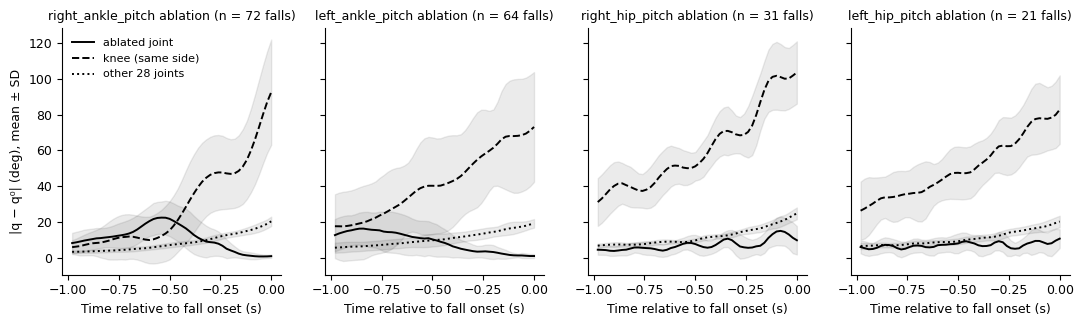

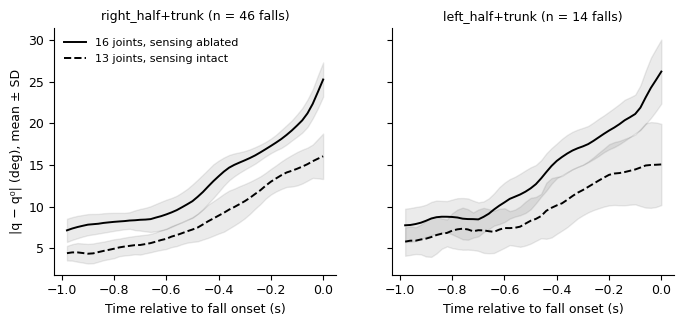

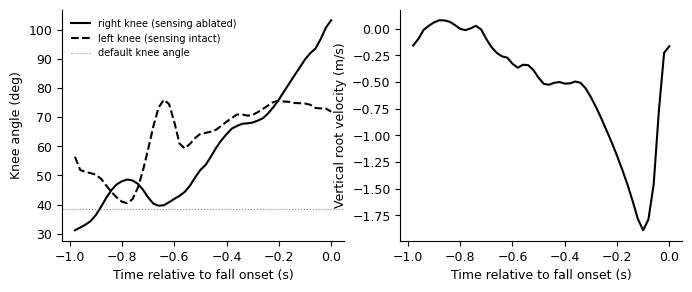

代表例:転倒ステップ 98、転倒開始時の右膝 103.2°、左膝 71.9°、基本姿勢 38.3°、上下速度 -0.16 m/s


In [16]:
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
DT = 0.02; WIN = 50                     # 転倒直前 50 ステップ = 1 秒
t_axis = (np.arange(-WIN + 1, 1)) * DT

def window(arr, k):
    seg = arr[max(0, k - WIN + 1): k + 1]
    if len(seg) < WIN:                  # 1秒未満で転倒した試行は先頭をNaNで埋める
        seg = np.concatenate([np.full((WIN - len(seg),) + seg.shape[1:], np.nan), seg])
    return seg

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.tiff", dpi=300, bbox_inches="tight")
    plt.show()

# 図F1:研究①
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, jn in zip(axes, P1_JOINTS):
    j = J[jn]; kn = J[KNEE_OF[jn]]; other = [i for i in range(29) if i != j]
    curves = {"ablated joint": [], "knee (same side)": [], "other 28 joints": []}
    for fpath in sorted(TRAJ_DIR.glob(f"P1_{jn}_seed*_v*.npz")):
        tr = dict(np.load(fpath)); k = int(tr["fall_step"]) - 1
        for key, idx in [("ablated joint", [j]), ("knee (same side)", [kn]), ("other 28 joints", other)]:
            curves[key].append(window(dev_deg(tr, idx)[0], k))
    for key, st in zip(curves, ["-", "--", ":"]):
        if curves[key]:
            a = np.array(curves[key]); m, s = np.nanmean(a, 0), np.nanstd(a, 0)
            ax.plot(t_axis, m, st, color="k", lw=1.4, label=key); ax.fill_between(t_axis, m - s, m + s, color="k", alpha=0.08)
    ax.set_title(f"{jn.replace('_joint','')} ablation (n = {len(curves['ablated joint'])} falls)", fontsize=9)
    ax.set_xlabel("Time relative to fall onset (s)")
axes[0].set_ylabel("|q − q⁰| (deg), mean ± SD"); axes[0].legend(frameon=False, fontsize=8)
savefig(fig, "F1_paper1_prefall_deviation")

# 図F2:研究②
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, (cond, idx) in zip(axes, P2_CONDITIONS.items()):
    intact = [i for i in range(29) if i not in idx]
    curves = {"16 joints, sensing ablated": [], "13 joints, sensing intact": []}
    for fpath in sorted(TRAJ_DIR.glob(f"P2_{cond}_seed*_v*.npz")):
        tr = dict(np.load(fpath)); k = int(tr["fall_step"]) - 1
        curves["16 joints, sensing ablated"].append(window(dev_deg(tr, idx)[0], k))
        curves["13 joints, sensing intact"].append(window(dev_deg(tr, intact)[0], k))
    for key, st in zip(curves, ["-", "--"]):
        if curves[key]:
            a = np.array(curves[key]); m, s = np.nanmean(a, 0), np.nanstd(a, 0)
            ax.plot(t_axis, m, st, color="k", lw=1.4, label=key); ax.fill_between(t_axis, m - s, m + s, color="k", alpha=0.08)
    ax.set_title(f"{cond} (n = {len(curves['16 joints, sensing ablated'])} falls)", fontsize=9)
    ax.set_xlabel("Time relative to fall onset (s)")
axes[0].set_ylabel("|q − q⁰| (deg), mean ± SD"); axes[0].legend(frameon=False, fontsize=8)
savefig(fig, "F2_paper2_prefall_deviation")

# 図F3:研究②の代表例(右半身+体幹、seed 1、0.5 m/s)
rep = TRAJ_DIR / "P2_right_half+trunk_seed1_v5.npz"
if rep.exists():
    tr = dict(np.load(rep)); k = int(tr["fall_step"]) - 1
    rk, lk = J["right_knee_joint"], J["left_knee_joint"]
    vz = np.gradient(tr["height"], DT)
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.0))
    axes[0].plot(t_axis, window(np.degrees(tr["q"][:, rk]), k), "-", color="k", label="right knee (sensing ablated)")
    axes[0].plot(t_axis, window(np.degrees(tr["q"][:, lk]), k), "--", color="k", label="left knee (sensing intact)")
    axes[0].axhline(np.degrees(tr["q0"][rk]), color="grey", lw=0.8, ls=":", label="default knee angle")
    axes[0].set_ylabel("Knee angle (deg)"); axes[0].legend(frameon=False, fontsize=7)
    axes[1].plot(t_axis, window(vz, k), color="k"); axes[1].set_ylabel("Vertical root velocity (m/s)")
    for ax in axes: ax.set_xlabel("Time relative to fall onset (s)")
    savefig(fig, "F3_paper2_representative_trial")
    print(f"代表例:転倒ステップ {k+1}、転倒開始時の右膝 {np.degrees(tr['q'][k, rk]):.1f}°、左膝 {np.degrees(tr['q'][k, lk]):.1f}°、"
          f"基本姿勢 {np.degrees(tr['q0'][rk]):.1f}°、上下速度 {vz[k]:.2f} m/s")
else:
    print("代表例(右半身+体幹、seed 1、0.5 m/s)は転倒しなかったため、図F3は作成しません")

In [17]:
#セル3:補足動画S1〜S4(§Gの前に入れる)
#4関節それぞれについて、代表的な転倒1例を動画にします(約5分)。代表例は、再測定で転倒した

%pip install -q mediapy
import mediapy as media
from IPython.display import Video, display

VIDEO_DIR = OUT_DIR / "videos"; VIDEO_DIR.mkdir(exist_ok=True)
VIDEO_CASES = [   # (除去する関節, seed, 速度, 再測定での転倒ステップ)
    ("right_ankle_pitch_joint", 3, 0.5, 86),
    ("left_ankle_pitch_joint", 1, 0.5, 98),
    ("right_hip_pitch_joint", 3, 0.8, 146),
    ("left_hip_pitch_joint", 3, 0.8, 138),
]
EXTRA_STEPS = 25   # 転倒の判定の後も、0.5秒間撮り続ける

def record_fall_video(jn, seed, speed):
    cfg = load_env_cfg(TASK, play=True)
    cfg.scene.num_envs = 1
    cfg.seed = ENV_SEED
    cfg.events["reset_base"].params["pose_range"]["yaw"] = (RIGHT_FACING_YAW_RAD, RIGHT_FACING_YAW_RAD)
    cfg.terminations.pop("fell_over", None)        # 自動リセットを起こさない
    agent_cfg = load_rl_cfg(TASK)
    raw_env = ManagerBasedRlEnv(cfg=cfg, device=DEVICE, render_mode="rgb_array")
    env = RslRlVecEnvWrapper(raw_env, clip_actions=agent_cfg.clip_actions)
    runner = MjlabOnPolicyRunner(env, asdict(agent_cfg), device=DEVICE)
    runner.load(str(latest_ckpt(seed)), load_cfg={"actor": True}, strict=True, map_location=DEVICE)
    policy = runner.get_inference_policy(device=DEVICE)
    with torch.no_grad():                            # §Bと同じ除去(重み行とバイアスを0にする)
        fl = runner.alg.actor.mlp[-1]
        fl.weight[J[jn], :] = 0.0
        fl.bias[J[jn]] = 0.0
    cmd = torch.tensor([[speed, 0.0, 0.0]], device=DEVICE)
    obs = env.get_observations(); frames = []; fall_step = -1
    for step in range(STEPS + EXTRA_STEPS):
        raw_env.command_manager.get_term("twist").vel_command_b[:] = cmd
        with torch.no_grad():
            obs, _, _, _ = env.step(policy(obs))
        fr = np.asarray(raw_env.render())
        frames.append(fr[0] if fr.ndim == 4 else fr)
        if fall_step < 0 and float(tilt_rad(raw_env)[0]) > FALL_LIMIT_RAD:
            fall_step = step + 1
        if (fall_step > 0 and step + 1 >= fall_step + EXTRA_STEPS) or (fall_step < 0 and step + 1 >= STEPS):
            break
    close_all(env); del runner, policy, env, raw_env
    name = f"Supplementary_Video_{jn.replace('_joint', '')}_seed{seed}_v{int(round(speed * 10)):02d}.mp4"
    media.write_video(str(VIDEO_DIR / name), frames, fps=50)   # 制御周期0.02秒 = 50 fps(実時間で再生)
    return VIDEO_DIR / name, fall_step

for i, (jn, seed, speed, expected) in enumerate(VIDEO_CASES, start=1):
    path, fs = record_fall_video(jn, seed, speed)
    print(f"S{i}: {jn} seed{seed} {speed} m/s → 転倒ステップ {fs}(再測定では {expected})  {path.name}")
    display(Video(str(path), embed=True, width=480))

Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

Setting seed: 100

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 1      |
| Environment device     | cuda:0 |
| Environment seed       | 100    |
| Physics step-size      | 0.005  |
| Environment step-size  | 0.02   |
+------------------------+--------+

[INFO] <EventManager> contains 2 active terms.
+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+--------+----------------------------+
| Index  | Name                       |
+--------+----------------------------+
|   0    | reset_base                 |
|   1    | reset_robot_joints         |
|   2    | randomize_terrain          |
+--------+----------------------------+
+---------------------------------------+
| Active Event Terms in Mode: 'startup' |
+-----------+---------------------------+
|   Index   | Name                      |
+--------

## §G. 結果の保存

`companion_remeasure_outputs.zip` を作り、Googleドライブにもコピーします。**このzipを共有してください。**

In [18]:
shutil.make_archive("companion_remeasure_outputs", "zip", OUT_DIR)
print("companion_remeasure_outputs.zip を作成しました")
try:
    shutil.copy("companion_remeasure_outputs.zip", "/content/drive/MyDrive/")
    print("Googleドライブ(マイドライブ直下)にもコピーしました")
except Exception as e:
    print("ドライブへのコピーはスキップ:", e)

companion_remeasure_outputs.zip を作成しました
Googleドライブ(マイドライブ直下)にもコピーしました
